# S11 · MRS voxel microstructure


In [1]:
from pathlib import Path
import sys
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
# Paths
bb_gradient_path = (
    f"{base_path}/DATA/cytoarchitecture/bb_gradient_df.csv"
)

parcel_cyto_path = (
    f"{base_path}/DATA/cytoarchitecture/parcel_cyto_df.csv"
)

selected_parcels_path = (
    f"{base_path}/DATA/discovery_dataset/"
    "selected_parcels_overlap30.csv"
)

output_dir = (
    f"{base_path}/FIGURES/supplementary/Fig_S11"
)

os.makedirs(output_dir, exist_ok=True)

# Colors
van_ec_colors = {
    1: "#7f297e",
    2: "#37699c",
    3: "#aad58c",
    4: "#fcce0c",
    5: "#f4ee1d",
}

# Voxel order and labels
voxel_order = [
    "anteriorcingulate",
    "occipital",
    "rightauditory",
    "smleft"
]

voxel_labels = ["ACC", "OCC", "rAUD", "lSMN"]

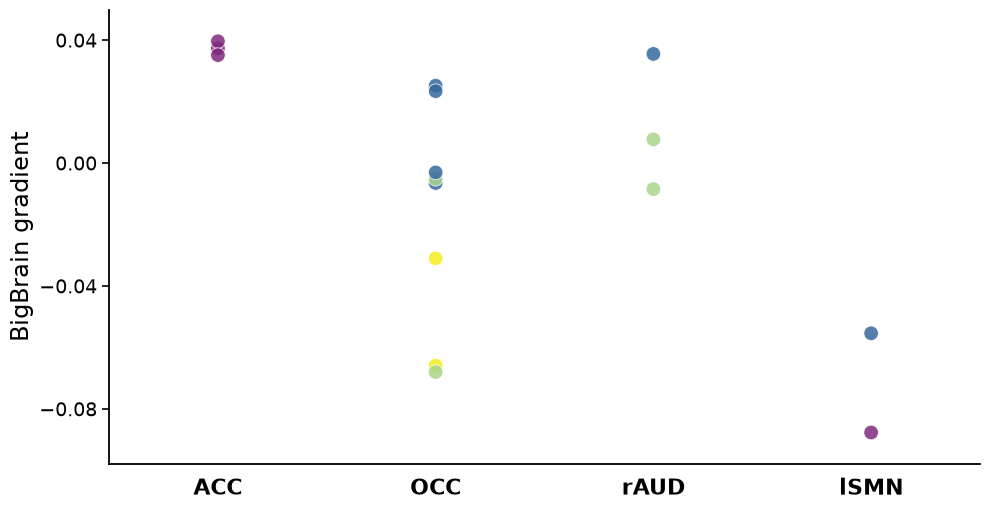

In [4]:
# Load data
bb_gradient = pd.read_csv(bb_gradient_path)
parcel_cyto = pd.read_csv(parcel_cyto_path)
selected_parcels = pd.read_csv(selected_parcels_path)

# Prepare plotting dataframe
# Keep only the voxels of interest
plot_df = selected_parcels[
    selected_parcels["voxel"].isin(voxel_order)
].copy()

# Make sure parcel_id is integer
plot_df["parcel_id"] = plot_df["parcel_id"].astype(int)

# Merge BigBrain gradient values by parcel
plot_df = plot_df.merge(
    bb_gradient[["Parcel", "Cyto_class"]].rename(
        columns={
            "Parcel": "parcel_id",
            "Cyto_class": "gradient"
        }
    ),
    on="parcel_id",
    how="left",
    validate="many_to_one"
)

# Merge cytoarchitecture classes by parcel
plot_df = plot_df.merge(
    parcel_cyto[["Parcel", "Cyto_class"]].rename(
        columns={
            "Parcel": "parcel_id",
            "Cyto_class": "cyto_class"
        }
    ),
    on="parcel_id",
    how="left",
    validate="many_to_one"
)

# Validate merged data
if plot_df["gradient"].isna().any():
    missing_ids = plot_df.loc[plot_df["gradient"].isna(), "parcel_id"].unique()
    raise ValueError(
        f"Missing BigBrain gradient values for parcel(s): {missing_ids}"
    )

if plot_df["cyto_class"].isna().any():
    missing_ids = plot_df.loc[plot_df["cyto_class"].isna(), "parcel_id"].unique()
    raise ValueError(
        f"Missing cytoarchitecture classes for parcel(s): {missing_ids}"
    )

# Convert cyto classes to integer
plot_df["cyto_class"] = plot_df["cyto_class"].astype(int)

# Map colors
plot_df["color"] = plot_df["cyto_class"].map(van_ec_colors)

if plot_df["color"].isna().any():
    bad_classes = sorted(plot_df.loc[plot_df["color"].isna(), "cyto_class"].unique())
    raise ValueError(
        f"Unknown von Economo class detected: {bad_classes}"
    )

# Common y limits

ymin = plot_df["gradient"].min()
ymax = plot_df["gradient"].max()

y_margin = 0.08 * (ymax - ymin)

common_ylim = (
    ymin - y_margin,
    ymax + y_margin
)

# Plot
fig, ax = plt.subplots(figsize=(10, 5.2))

# Reproducible jitter
rng = np.random.default_rng(42)

for x, voxel_name in enumerate(voxel_order):

    voxel_df = plot_df.loc[
        plot_df["voxel"] == voxel_name
    ].copy()

    # Small horizontal jitter to avoid overlaps if needed
    jitter = rng.normal(
        loc=0,
        scale=0.0,   # keep zero to preserve original style
        size=len(voxel_df)
    )

    x_positions = x + jitter

    ax.scatter(
        x_positions,
        voxel_df["gradient"],
        c=voxel_df["color"].tolist(),
        s=110,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.6,
        zorder=3,
    )

# Axes
ax.set_xlim(-0.5, len(voxel_order) - 0.5)
ax.set_ylim(common_ylim)

ax.set_xticks(range(len(voxel_order)))
ax.set_xticklabels(
    voxel_labels,
    fontsize=16,
    fontweight="bold",
)

ax.set_ylabel(
    "BigBrain gradient",
    fontsize=17,
    fontweight="normal",
)

ax.set_yticks([-0.08, -0.04, 0, 0.04])

ax.tick_params(
    axis="y",
    labelsize=14,
    length=5,
    width=1.2,
)

ax.tick_params(
    axis="x",
    length=0,
    pad=10,
)

# Style

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.3)
ax.spines["bottom"].set_linewidth(1.3)

fig.tight_layout()

# Save

png_path = os.path.join(
    output_dir,
    "gradient_classes_all_voxels.png"
)

pdf_path = os.path.join(
    output_dir,
    "gradient_classes_all_voxels.pdf"
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches="tight",
    transparent=False,
    facecolor="white",
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    transparent=False,
    facecolor="white",
)

plt.show()
plt.close(fig)